In [10]:
pip install kagglehub[pandas-datasets]


   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   -------------------- ------------------- 1/2 [kagglehub]
   ---------------------------------------- 2/2 [kagglehub]

Note: you may need to restart the kernel to use updated packages.


In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")

print("Path to dataset files:", path)

100%|██████████| 50.1k/50.1k [00:00<00:00, 246kB/s]

Extracting files...
Path to dataset files: C:\Users\Minhal\.cache\kagglehub\datasets\pavansubhasht\ibm-hr-analytics-attrition-dataset\versions\1


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, ConfusionMatrixDisplay

In [16]:
url = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"

df = pd.read_csv(url)
print("Dataset loaded")
print(df.shape)
df.head()

Dataset loaded
(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [17]:
features = [
    "Age",
    "JobLevel",
    "MonthlyIncome",
    "YearsAtCompany",
    "JobSatisfaction",
    "OverTime",
    "JobRole",
    "MaritalStatus"
]
df = df[features + ["Attrition"]]
print(df.head())
print()
print("Missing values:")
print(df.isnull().sum())

   Age  JobLevel  MonthlyIncome  YearsAtCompany  JobSatisfaction OverTime  \
0   41         2           5993               6                4      Yes   
1   49         2           5130              10                2       No   
2   37         1           2090               0                3      Yes   
3   33         1           2909               8                3      Yes   
4   27         1           3468               2                2       No   

                 JobRole MaritalStatus Attrition  
0        Sales Executive        Single       Yes  
1     Research Scientist       Married        No  
2  Laboratory Technician        Single       Yes  
3     Research Scientist       Married        No  
4  Laboratory Technician       Married        No  

Missing values:
Age                0
JobLevel           0
MonthlyIncome      0
YearsAtCompany     0
JobSatisfaction    0
OverTime           0
JobRole            0
MaritalStatus      0
Attrition          0
dtype: int64


In [18]:
df = df.dropna()
df["Attrition"] = df["Attrition"].map({"No": 0, "Yes": 1})
df = pd.get_dummies(
    df,
    columns=["OverTime", "JobRole", "MaritalStatus"],
    drop_first=True
)
print(df.head())
print()
print("Dataset shape after encoding:", df.shape)

   Age  JobLevel  MonthlyIncome  YearsAtCompany  JobSatisfaction  Attrition  \
0   41         2           5993               6                4          1   
1   49         2           5130              10                2          0   
2   37         1           2090               0                3          1   
3   33         1           2909               8                3          0   
4   27         1           3468               2                2          0   

   OverTime_Yes  JobRole_Human Resources  JobRole_Laboratory Technician  \
0          True                    False                          False   
1         False                    False                          False   
2          True                    False                           True   
3          True                    False                          False   
4         False                    False                           True   

   JobRole_Manager  JobRole_Manufacturing Director  JobRole_Research Direc

In [19]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1176, 16)
Testing data: (294, 16)


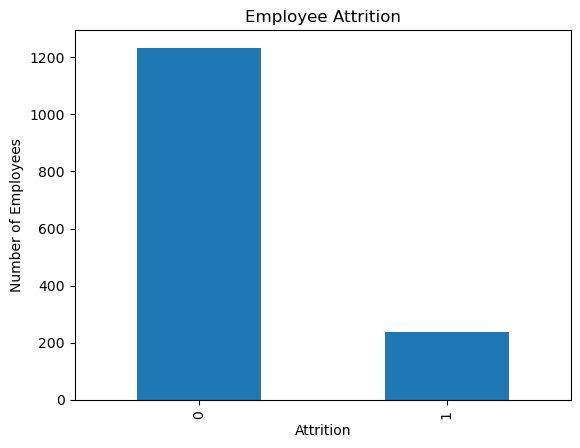

In [20]:
y.value_counts().plot(kind="bar")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.title("Employee Attrition")
plt.show()

In [21]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)
logistic_prediction = logistic_model.predict(X_test_scaled)
logistic_accuracy = accuracy_score(y_test, logistic_prediction)
logistic_f1 = f1_score(y_test, logistic_prediction)
print("Logistic Regression Accuracy:", round(logistic_accuracy, 3))
print("Logistic Regression F1 Score:", round(logistic_f1, 3))

Logistic Regression Accuracy: 0.864
Logistic Regression F1 Score: 0.375


In [22]:
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)
tree_model.fit(X_train, y_train)
tree_prediction = tree_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_prediction)
tree_f1 = f1_score(y_test, tree_prediction)

print("Decision Tree Accuracy:", round(tree_accuracy, 3))
print("Decision Tree F1 Score:", round(tree_f1, 3))

Decision Tree Accuracy: 0.83
Decision Tree F1 Score: 0.324


In [23]:
forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
forest_model.fit(X_train, y_train)
forest_prediction = forest_model.predict(X_test)
forest_accuracy = accuracy_score(y_test, forest_prediction)
forest_f1 = f1_score(y_test, forest_prediction)

print("Random Forest Accuracy:", round(forest_accuracy, 3))
print("Random Forest F1 Score:", round(forest_f1, 3))

Random Forest Accuracy: 0.827
Random Forest F1 Score: 0.261


In [24]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        forest_accuracy
    ],
    "F1 Score": [
        logistic_f1,
        tree_f1,
        forest_f1
    ]
})
print(results)

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.863946  0.375000
1        Decision Tree  0.829932  0.324324
2        Random Forest  0.826531  0.260870


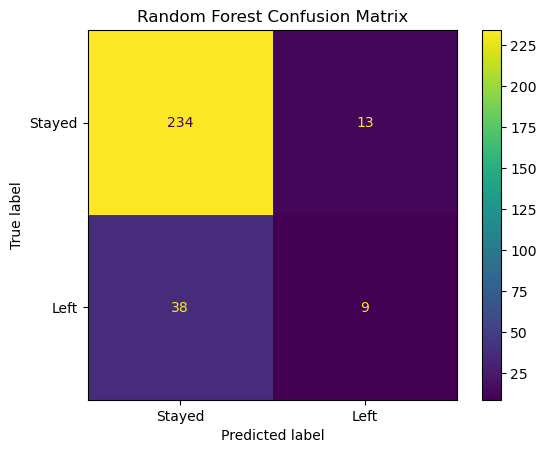

In [25]:
cm = confusion_matrix(y_test, forest_prediction)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)
display.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

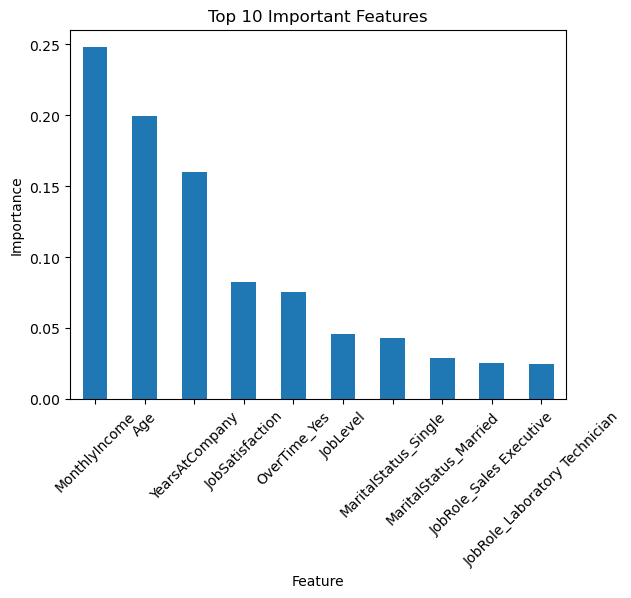

In [26]:
importance = pd.Series(
    forest_model.feature_importances_,
    index=X.columns
)
importance = importance.sort_values(ascending=False).head(10)
importance.plot(kind="bar")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Top 10 Important Features")
plt.xticks(rotation=45)
plt.show()